# TPE · EPA Fuel Economy 2025
## 1. Análisis exploratorio inicial

El análisis explora la estructura de la base, las características de sus atributos, las distribuciones, los valores faltantes, las repeticiones y los valores extremos. También examina las relaciones entre las características técnicas de los vehículos y su economía de combustible. La base original se conserva para identificar qué aspectos requieren tratamiento en la etapa de limpieza.

**Contenido:** 1. Análisis exploratorio · 2. Limpieza · 3. Hipótesis propuestas · 4. Validación de hipótesis.

### 1.1. Contexto y lectura de los datos

El conjunto EPA Fuel Economy contiene resultados de ensayos de vehículos de año modelo 2025 realizados por la Environmental Protection Agency (EPA) de Estados Unidos y por fabricantes que reportan sus resultados al organismo. Estos ensayos forman parte del proceso de determinación de las estimaciones oficiales de economía de combustible.

La base combina características de los vehículos —como motorización, transmisión, tracción y peso— con las condiciones y los resultados de cada ensayo. La economía de combustible expresa la distancia recorrida por unidad de combustible: un mayor valor en MPG indica una mayor eficiencia.

Se analiza el archivo `25-testcar-2026-01-21.xlsx`, hoja `Sheet1`. El año modelo identifica a los vehículos representados y no debe confundirse con la fecha de realización de cada ensayo.

Primero se inspeccionan las dimensiones, las primeras filas y los tipos de datos para comprobar la estructura antes de calcular estadísticas.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option('display.max_columns', 12)
pd.set_option('display.max_colwidth', 70)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 11})

# Ejecutar desde la raíz del proyecto; el archivo original se conserva en data/.
archivo = Path('data') / '25-testcar-2026-01-21.xlsx'
libro = pd.ExcelFile(archivo)
print('Hojas:', libro.sheet_names)
datos = pd.read_excel(archivo, sheet_name='Sheet1')
print(f'Dimensiones: {datos.shape[0]:,} registros y {datos.shape[1]} atributos')
display(datos.head())
datos.info()

Matplotlib is building the font cache; this may take a moment.


Hojas: ['Sheet1']


Dimensiones: 4,287 registros y 67 atributos


,Model Year,Vehicle Manufacturer Name,Veh Mfr Code,Represented Test Veh Make,Represented Test Veh Model,Test Vehicle ID,...,Aftertreatment Device Desc,Police - Emergency Vehicle?,Averaging Group ID,Averaging Weighting Factor,Averaging Method Cd,Averging Method Desc
0,2025,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,...,Three-way catalyst,N,NaN,NaN,N,No averaging
1,2025,aston martin,ASX,Aston Martin,DB12 V8,5723PT5601,...,Three-way catalyst,N,NaN,NaN,N,No averaging
2,2025,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,...,Three-way catalyst,N,NaN,NaN,N,No averaging
3,2025,aston martin,ASX,Aston Martin,DBX 707,8841PT8473,...,Three-way catalyst,N,NaN,NaN,N,No averaging
4,2025,aston martin,ASX,Aston Martin,Vanquish,370TT7334,...,Three-way catalyst,N,NaN,NaN,N,No averaging


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4287 entries, 0 to 4286
Data columns (total 67 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Model Year                      4287 non-null   int64  
 1   Vehicle Manufacturer Name       4287 non-null   object 
 2   Veh Mfr Code                    4287 non-null   object 
 3   Represented Test Veh Make       4287 non-null   object 
 4   Represented Test Veh Model      4287 non-null   object 
 5   Test Vehicle ID                 4287 non-null   object 
 6   Test Veh Configuration #        4287 non-null   int64  
 7   Test Veh Displacement (L)       4287 non-null   float64
 8   Actual Tested Testgroup         4287 non-null   object 
 9   Vehicle Type                    4287 non-null   object 
 10  Rated Horsepower                4287 non-null   int64  
 11  # of Cylinders and Rotors       3617 non-null   float64
 12  Engine Code                     42

### 1.2. Unidad de observación y repeticiones

Cada fila registra una configuración sometida a ensayo. La combinación `Veh Mfr Code` + `Test Vehicle ID` + `Test Veh Configuration #` identifica una configuración. Un vehículo puede tener varias configuraciones y una configuración varios ensayos. Por eso, los recuentos de filas describen **registros**, no cantidades de automóviles vendidos ni preferencias de consumidores.

Revisamos por separado filas completamente idénticas, configuraciones repetidas y números de ensayo repetidos. La repetición de una clave no justifica por sí sola eliminar una fila.

In [2]:
clave_config = ['Veh Mfr Code', 'Test Vehicle ID', 'Test Veh Configuration #']
resumen_unidades = pd.Series({
    'Registros': len(datos),
    'Identificadores de vehículo distintos (sin fabricante)': datos['Test Vehicle ID'].nunique(),
    'Vehículos identificados con fabricante': datos[clave_config[:2]].drop_duplicates().shape[0],
    'Configuraciones distintas': datos[clave_config].drop_duplicates().shape[0],
    'Números de ensayo distintos': datos['Test Number'].nunique(),
    'Filas completamente duplicadas': int(datos.duplicated().sum()),
    'Repeticiones de Test Number posteriores a la primera': int(datos['Test Number'].duplicated().sum())
}, name='Cantidad')
display(resumen_unidades.to_frame())
display(datos.groupby(clave_config).size().describe().to_frame('Registros por configuración'))

# Para cada número repetido identificamos qué atributos varían entre sus filas.
repetidos = datos[datos['Test Number'].duplicated(keep=False)]
variaciones = repetidos.groupby('Test Number').nunique(dropna=False)
cambios = variaciones.gt(1)
display(cambios.sum().loc[lambda s: s > 0].to_frame('Números de ensayo con diferencias'))
ejemplo = repetidos['Test Number'].iloc[0]
columnas_ejemplo = ['Test Number'] + clave_config + ['Test Category'] + cambios.columns[cambios.loc[ejemplo]].tolist()
display(datos.loc[datos['Test Number'].eq(ejemplo), columnas_ejemplo])

,Cantidad
Registros,4287
Identificadores de vehículo distintos (sin fabricante),953
Vehículos identificados con fabricante,953
Configuraciones distintas,1448
Números de ensayo distintos,4014
Filas completamente duplicadas,0
Repeticiones de Test Number posteriores a la primera,273


,Registros por configuración
count,1448.000000
mean,2.960635
std,1.912523
min,1.000000
25%,2.000000
50%,2.000000
75%,4.000000
max,16.000000


,Números de ensayo con diferencias
Transmission Overdrive Code,2
Transmission Overdrive Desc,2
Set Coef A (lbf),34
Set Coef B (lbf/mph),34
Set Coef C (lbf/mph**2),34
Aftertreatment Device Cd,177
Aftertreatment Device Desc,177


,Test Number,Veh Mfr Code,Test Vehicle ID,Test Veh Configuration #,Test Category,Aftertreatment Device Cd,Aftertreatment Device Desc
12,SBMX10086268,BMX,8D89453,0,FTP,OT,Other
13,SBMX10086268,BMX,8D89453,0,FTP,TWC,Three-way catalyst


**Interpretación.** Hay 4.287 filas, 1.448 configuraciones y 4.014 números de ensayo distintos; no hay filas idénticas. `Test Number` identifica al ensayo, pero no constituye una clave única de esta tabla. En los números repetidos varían atributos de postratamiento, coeficientes de ajuste o sobremarcha. La causa de esa representación no está confirmada. Conservar todas las filas permite documentar el problema antes de decidir su tratamiento; varias filas por ensayo pueden dar más peso a algunos ensayos en las estadísticas.

### 1.3. Caracterización de los 67 atributos

El tipo computacional (`int64`, `float64`, `object`) describe el almacenamiento, no la escala estadística. Un código numérico de combustible o procedimiento es **nominal**: su promedio no tiene interpretación. Los identificadores se distinguen de las mediciones. El año modelo es temporal discreto y constante en esta base; cilindros y marchas son conteos discretos; las medidas físicas se tratan como continuas. Las banderas sí/no son nominales dicotómicas.

La siguiente tabla documenta todas las columnas con su significado, escala, unidad, cardinalidad y ausencias. Cuando la unidad de una medida no está especificada, se señala en la tabla.

In [3]:
definiciones = [('Año modelo', 'Temporal discreta', 'año'), ('Fabricante', 'Nominal', '—'), ('Código EPA de fabricante', 'Identificador', '—'), ('Marca representada', 'Nominal', '—'), ('Modelo representado', 'Nominal', '—'), ('Vehículo de ensayo', 'Identificador', '—'), ('Configuración del vehículo', 'Identificador', '—'), ('Cilindrada', 'Continua', 'L'), ('Familia/grupo de ensayo', 'Identificador', '—'), ('Tipo de vehículo', 'Nominal', '—'), ('Potencia nominal', 'Continua', 'HP'), ('Cantidad de cilindros o rotores', 'Discreta', 'conteo'), ('Código de motor', 'Nominal', '—'), ('Código de transmisión', 'Nominal', '—'), ('Tipo de transmisión', 'Nominal', '—'), ('Cantidad de marchas', 'Discreta', 'conteo'), ('Función lock-up', 'Nominal dicotómica', '—'), ('Código de tracción', 'Nominal', '—'), ('Sistema de tracción', 'Nominal', '—'), ('Código de sobremarcha', 'Nominal', '—'), ('Descripción de sobremarcha', 'Nominal', '—'), ('Peso equivalente de ensayo', 'Continua', 'lb'), ('Relación de eje', 'Continua', 'relación'), ('Relación N/V', 'Continua', 'relación'), ('Código de indicador de cambio', 'Nominal', '—'), ('Descripción de indicador de cambio', 'Nominal', '—'), ('Número de ensayo', 'Identificador', '—'), ('Organismo que origina el ensayo', 'Nominal', '—'), ('Economía derivada analíticamente', 'Nominal dicotómica', '—'), ('Ensayo asociado a ADFE', 'Identificador', '—'), ('Potencia de road load asociada a ADFE', 'Continua', 'HP'), ('Peso equivalente asociado a ADFE', 'Continua', 'lb'), ('Relación N/V asociada a ADFE', 'Continua', 'relación'), ('Código de procedimiento', 'Nominal', '—'), ('Procedimiento de ensayo', 'Nominal', '—'), ('Código de combustible', 'Nominal', '—'), ('Combustible/fuente de energía', 'Nominal', '—'), ('Categoría de ensayo', 'Nominal', '—'), ('Hidrocarburos totales', 'Continua', 'g/mi'), ('Monóxido de carbono', 'Continua', 'g/mi'), ('Dióxido de carbono', 'Continua', 'g/mi'), ('Óxidos de nitrógeno', 'Continua', 'g/mi'), ('Material particulado', 'Continua', 'g/mi'), ('Metano', 'Continua', 'g/mi'), ('Óxido nitroso', 'Continua', 'g/mi'), ('Economía ajustada/redondeada del ensayo', 'Continua', 'MPG según archivo'), ('Unidad declarada de economía', 'Nominal', '—'), ('Economía en fase/bolsa 1', 'Continua', 'MPG según metadatos'), ('Economía en fase/bolsa 2', 'Continua', 'MPG según metadatos'), ('Economía en fase/bolsa 3', 'Continua', 'MPG según metadatos'), ('Economía en fase/bolsa 4', 'Continua', 'MPG según metadatos'), ('Calificación de relación de trabajo de inercia', 'Continua', 'no explicitada'), ('Calificación de cambio absoluto de velocidad', 'Continua', 'no explicitada'), ('Calificación de economía de energía', 'Continua', 'no explicitada'), ('Coeficiente objetivo A de resistencia al avance', 'Continua', 'lbf'), ('Coeficiente objetivo B de resistencia al avance', 'Continua', 'lbf/mph'), ('Coeficiente objetivo C de resistencia al avance', 'Continua', 'lbf/mph²'), ('Coeficiente ajustado A de resistencia al avance', 'Continua', 'lbf'), ('Coeficiente ajustado B de resistencia al avance', 'Continua', 'lbf/mph'), ('Coeficiente ajustado C de resistencia al avance', 'Continua', 'lbf/mph²'), ('Código de postratamiento', 'Nominal', '—'), ('Dispositivo de postratamiento', 'Nominal', '—'), ('Vehículo policial/de emergencia', 'Nominal dicotómica', '—'), ('Grupo de promediado', 'Identificador', '—'), ('Factor de ponderación del promediado', 'Continua', 'factor'), ('Código de método de promediado', 'Nominal', '—'), ('Descripción de método de promediado', 'Nominal', '—')]
diccionario = pd.DataFrame(definiciones, columns=['Significado', 'Escala', 'Unidad'], index=datos.columns)
diccionario['Tipo Python'] = datos.dtypes.astype(str)
diccionario['Valores distintos'] = datos.nunique(dropna=True)
diccionario['Nulos'] = datos.isna().sum()
with pd.option_context('display.max_rows', 80, 'display.max_colwidth', 55):
    display(diccionario)
print('Atributos constantes entre los valores observados:')
display(diccionario.loc[diccionario['Valores distintos'].eq(1)])

,Significado,Escala,Unidad,Tipo Python,Valores distintos,Nulos
Model Year,Año modelo,Temporal discreta,año,int64,1,0
Vehicle Manufacturer Name,Fabricante,Nominal,—,object,32,0
Veh Mfr Code,Código EPA de fabricante,Identificador,—,object,32,0
Represented Test Veh Make,Marca representada,Nominal,—,object,60,0
Represented Test Veh Model,Modelo representado,Nominal,—,object,880,0
Test Vehicle ID,Vehículo de ensayo,Identificador,—,object,953,0
Test Veh Configuration #,Configuración del vehículo,Identificador,—,int64,9,0
Test Veh Displacement (L),Cilindrada,Continua,L,float64,55,0
Actual Tested Testgroup,Familia/grupo de ensayo,Identificador,—,object,563,0
Vehicle Type,Tipo de vehículo,Nominal,—,object,3,0


Atributos constantes entre los valores observados:


,Significado,Escala,Unidad,Tipo Python,Valores distintos,Nulos
Model Year,Año modelo,Temporal discreta,año,int64,1,0
FE_UNIT,Unidad declarada de economía,Nominal,—,object,1,0
Averaging Weighting Factor,Factor de ponderación del promediado,Continua,factor,float64,1,4212


`Model Year` y `FE_UNIT` son constantes completas. El factor de ponderación también tiene un único valor observado, pero muchos nulos: **constante entre valores disponibles no equivale a completo**. El nombre original `Averging Method Desc` se conserva para permitir rastrear la columna al Excel.

,Atributo,Valor,Registros,Porcentaje
972,Vehicle Type,Truck,2030,47.35
973,Vehicle Type,Car,1631,38.05
974,Vehicle Type,Both,626,14.60


,Atributo,Valor,Registros,Porcentaje
1581,Test Fuel Type Description,Tier 2 Cert Gasoline,3236,75.48
1582,Test Fuel Type Description,Electricity,654,15.26
1583,Test Fuel Type Description,Cold CO Regular (Tier 2),160,3.73
1584,Test Fuel Type Description,Federal Cert Diesel 7-15 PPM Sulfur,150,3.50
1585,Test Fuel Type Description,Cold CO Premium (Tier 2),57,1.33
1586,Test Fuel Type Description,E85 (85% Ethanol 15% EPA Unleaded Gasoline),12,0.28
1587,Test Fuel Type Description,Hydrogen 5,10,0.23
1588,Test Fuel Type Description,Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.),3,0.07
1589,Test Fuel Type Description,Cold CO E10 Regular Gasoline (Tier 3),2,0.05
1590,Test Fuel Type Description,CARB LEV3 E10 Premium Gasoline,2,0.05


,Atributo,Valor,Registros,Porcentaje
1592,Test Category,FTP,1577,36.79
1593,Test Category,HWY,1340,31.26
1594,Test Category,CD,695,16.21
1595,Test Category,US06,412,9.61
1596,Test Category,SC03,263,6.13


,Atributo,Valor,Registros,Porcentaje
1556,Test Procedure Description,HWFE,1340,31.26
1557,Test Procedure Description,Federal fuel 2-day exhaust (w/can load),923,21.53
1558,Test Procedure Description,US06,412,9.61
1559,Test Procedure Description,Federal fuel 3-day exhaust,341,7.95
1560,Test Procedure Description,SC03,263,6.13
1561,Test Procedure Description,Charge Depleting Highway,239,5.57
1562,Test Procedure Description,Charge Depleting UDDS,237,5.53
1563,Test Procedure Description,Cold CO,224,5.23
1564,Test Procedure Description,Multi-Cycle Test (MCT),190,4.43
1565,Test Procedure Description,CVS 75 and later (w/o can. load),78,1.82


,Atributo,Valor,Registros,Porcentaje
1521,Drive System Description,All Wheel Drive,1459,34.03
1522,Drive System Description,"2-Wheel Drive, Front",1393,32.49
1523,Drive System Description,"2-Wheel Drive, Rear",957,22.32
1524,Drive System Description,4-Wheel Drive,405,9.45
1525,Drive System Description,Part-time 4-Wheel Drive,73,1.70


,Atributo,Valor,Registros,Porcentaje
1506,Tested Transmission Type,Automatic,1639,38.23
1507,Tested Transmission Type,Semi-Automatic,1220,28.46
1508,Tested Transmission Type,Continuously Variable,490,11.43
1509,Tested Transmission Type,Automated Manual- Selectable (e.g. Automated Manual with paddles),485,11.31
1510,Tested Transmission Type,Selectable Continuously Variable (e.g. CVT with paddles),171,3.99
1511,Tested Transmission Type,Manual,128,2.99
1512,Tested Transmission Type,Other,102,2.38
1513,Tested Transmission Type,Automated Manual,52,1.21


,Atributo,Valor,Registros,Porcentaje
1538,Test Originator,MFR,3839,89.55
1539,Test Originator,EPA,448,10.45


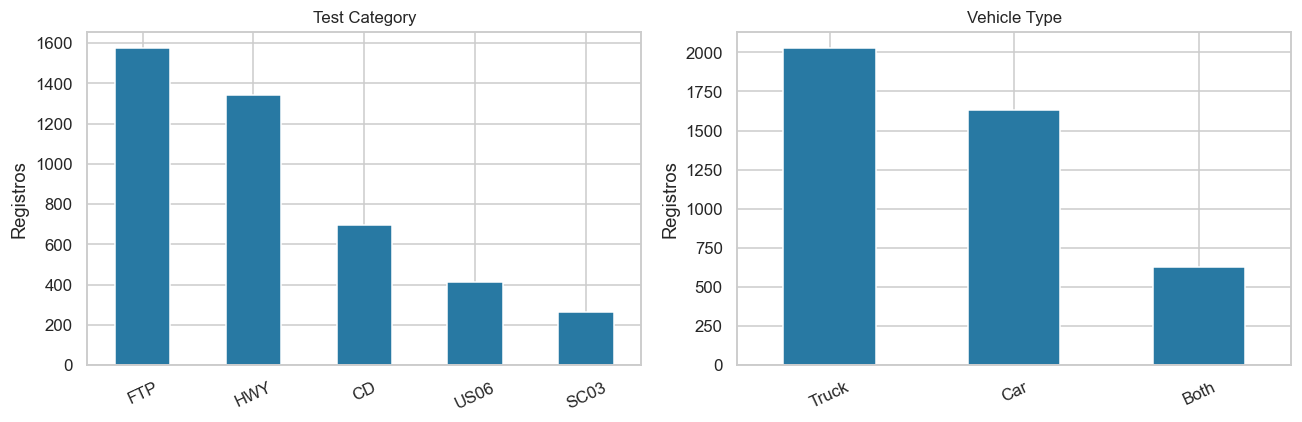

In [4]:
# Las frecuencias se expresan sobre el total de registros, incluyendo faltantes.
categoricas = diccionario.index[diccionario['Escala'].str.startswith('Nominal')]
frecuencias = []
for columna in categoricas:
    f = datos[columna].value_counts(dropna=False).rename_axis('Valor').reset_index(name='Registros')
    f.insert(0, 'Atributo', columna)
    f['Porcentaje'] = 100 * f['Registros'] / len(datos)
    frecuencias.append(f)
frecuencias = pd.concat(frecuencias, ignore_index=True)
for columna in ['Vehicle Type', 'Test Fuel Type Description', 'Test Category',
                'Test Procedure Description', 'Drive System Description', 'Tested Transmission Type', 'Test Originator']:
    display(frecuencias.loc[frecuencias['Atributo'].eq(columna)].round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, columna in zip(axes, ['Test Category', 'Vehicle Type']):
    datos[columna].value_counts().plot.bar(ax=ax, color='#2879a3')
    ax.set(title=columna, xlabel='', ylabel='Registros')
    ax.tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()

**Lectura.** Predominan `Tier 2 Cert Gasoline` (3.236 registros), `Truck` (2.030) y las categorías `FTP` (1.577) y `HWY` (1.340). Hay 11 combustibles/fuentes de energía y 14 procedimientos: una categoría resumida no identifica necesariamente un solo procedimiento. Estas proporciones describen la composición de los ensayos disponibles y no el parque automotor. Las etiquetas `Car`, `Truck` y `Both` se mantienen tal como fueron provistas.

### 1.4. Valores nulos y su contexto

Calculamos cantidad y porcentaje de nulos por atributo. Pandas reconoce celdas vacías como `NaN`; un cero numérico se conserva como valor. No suponemos que todos los faltantes tengan la misma causa. Contrastamos su patrón con las variables que indican si corresponde medir cada atributo.

,Nulos,% nulos
Averaging Weighting Factor,4212,98.25
Averaging Group ID,4212,98.25
ADFE Test Number,4075,95.05
ADFE N/V Ratio,4075,95.05
ADFE Total Road Load HP,4075,95.05
ADFE Equiv. Test Weight (lbs.),4075,95.05
FE Bag 4,3899,90.95
PM (g/mi),3898,90.93
FE Bag 3,2834,66.11
FE Bag 2,2423,56.52


Filas con al menos un nulo: 4287


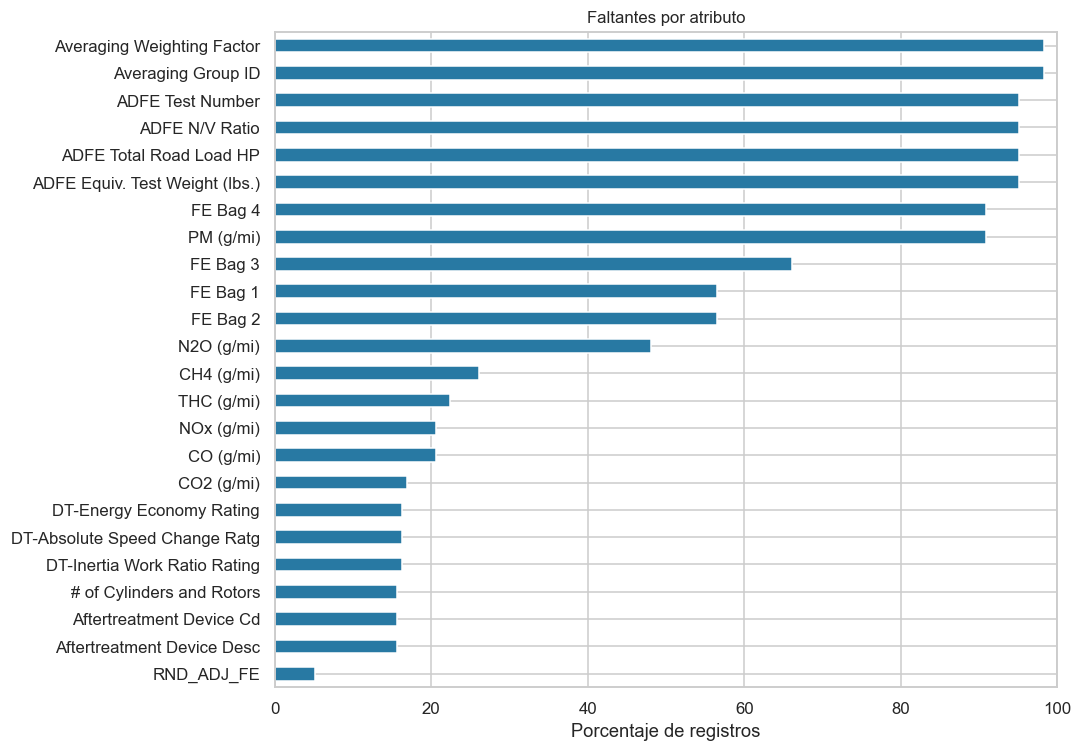

,ADFE Test Number,ADFE Total Road Load HP,ADFE Equiv. Test Weight (lbs.),ADFE N/V Ratio
Analytically Derived FE?,,,,
No,100.0,100.0,100.0,100.0
Yes,0.0,0.0,0.0,0.0


,# of Cylinders and Rotors,Aftertreatment Device Desc,RND_ADJ_FE
Test Fuel Type Description,,,
CARB LEV3 E10 Premium Gasoline,0,0,0
CARB LEV3 E10 Regular Gasoline,0,0,0
Cold CO E10 Regular Gasoline (Tier 3),0,0,0
Cold CO Premium (Tier 2),0,0,0
Cold CO Regular (Tier 2),0,0,0
E85 (85% Ethanol 15% EPA Unleaded Gasoline),0,0,0
Electricity,654,654,91
Federal Cert Diesel 7-15 PPM Sulfur,0,0,0
Hydrogen 5,10,10,0


,FE Bag 1,FE Bag 2,FE Bag 3,FE Bag 4,RND_ADJ_FE
Test Category,,,,,
CD,100.00,100.00,100.00,100.0,18.71
FTP,6.72,6.72,7.86,75.4,1.65
HWY,100.00,100.00,100.00,100.0,1.72
SC03,100.00,100.00,100.00,100.0,8.75
US06,4.61,4.61,100.00,100.0,4.61


,Averaging Group ID,Averaging Weighting Factor
Averging Method Desc,,
Harmonic averaging (1/(Sum(i=1 to n) (FET(i) / WT(i))),0.0,0.0
No averaging,100.0,100.0


In [5]:
faltantes = pd.DataFrame({'Nulos': datos.isna().sum(), '% nulos': datos.isna().mean() * 100})
faltantes = faltantes.sort_values('Nulos', ascending=False)
display(faltantes.loc[faltantes['Nulos'].gt(0)].round(2))
print('Filas con al menos un nulo:', int(datos.isna().any(axis=1).sum()))
fig, ax = plt.subplots(figsize=(10, 7))
faltantes.loc[faltantes['Nulos'].gt(0), '% nulos'].sort_values().plot.barh(ax=ax, color='#2879a3')
ax.set(xlabel='Porcentaje de registros', ylabel='', title='Faltantes por atributo', xlim=(0, 100))
plt.tight_layout(); plt.show()

adfe = ['ADFE Test Number', 'ADFE Total Road Load HP', 'ADFE Equiv. Test Weight (lbs.)', 'ADFE N/V Ratio']
display(datos[adfe].isna().groupby(datos['Analytically Derived FE?']).mean().mul(100).round(2))
cols_faltantes = ['# of Cylinders and Rotors', 'Aftertreatment Device Desc', 'RND_ADJ_FE']
display(datos[cols_faltantes].isna().groupby(datos['Test Fuel Type Description']).sum())
display(datos[['FE Bag 1','FE Bag 2','FE Bag 3','FE Bag 4','RND_ADJ_FE']].isna()
        .groupby(datos['Test Category']).mean().mul(100).round(2))
display(datos[['Averaging Group ID','Averaging Weighting Factor']].isna()
        .groupby(datos['Averging Method Desc']).mean().mul(100).round(2))

**Interpretación.** Las cuatro columnas ADFE tienen 4.075 nulos (95,05%), correspondientes a `Analytically Derived FE? = No`; los 212 registros `Yes` tienen esos campos completos. `Averaging Group ID` y `Averaging Weighting Factor` tienen 4.212 nulos, asociados a `No averaging`. Estas variables solo corresponden a los registros que utilizan esos métodos, lo que explica la concentración de ausencias en los demás casos.

En cilindros y postratamiento hay 670 nulos: 654 registros con `Electricity`, 10 con `Hydrogen 5` y 6 con gasolina. Ese patrón es compatible con distinta aplicabilidad, pero el archivo no documenta la causa individual de las ausencias. Las fases/bolsas tienen cobertura distinta según la categoría. `RND_ADJ_FE` tiene 221 nulos (5,16%); el análisis no los reemplaza por cero.

### 1.5. Distribuciones y estadística descriptiva

Seleccionamos medidas por su significado y excluimos códigos e identificadores. `count` informa el denominador efectivo por variable; `std` es el desvío muestral (ddof=1). Media y mediana describen el centro, los cuartiles la posición, y rango, desvío y rango intercuartílico (RIC) la dispersión. La asimetría y la curtosis se interpretan junto con los gráficos, especialmente cuando se mezclan grupos.

Los resúmenes globales sirven para detectar particularidades de la base. **No convierten a todos los ensayos en observaciones homogéneas.** En particular, un mayor MPG indica mayor eficiencia, pero no se interpreta sin más un ensayo eléctrico como si fuera uno de gasolina, aunque `FE_UNIT` diga MPG en todas las filas.

,count,mean,std,min,25%,50%,75%,max,Rango,RIC,Asimetría,Curtosis (exceso)
Test Veh Displacement (L),4287.0,4.688,14.572,0.001,1.991,2.487,3.000,99.999,99.998,1.009,6.328,38.477
Rated Horsepower,4287.0,340.698,175.122,1.000,201.000,305.000,409.000,1948.000,1947.000,208.000,1.589,5.051
# of Cylinders and Rotors,3617.0,5.222,1.624,3.000,4.000,4.000,6.000,16.000,13.000,2.000,1.182,1.815
# of Gears,4287.0,6.052,3.398,1.000,1.000,8.000,8.000,10.000,9.000,7.000,-0.638,-1.263
Equivalent Test Weight (lbs.),4287.0,4818.784,985.818,2750.000,4000.000,4750.000,5500.000,9000.000,6250.000,1500.000,0.587,0.352
Axle Ratio,4287.0,3.784,1.719,0.000,3.200,3.450,3.900,9.990,9.990,0.700,1.811,4.905
N/V Ratio,4287.0,57.373,142.382,0.000,23.300,25.700,30.100,999.000,999.000,6.800,6.149,37.683
ADFE Total Road Load HP,212.0,17.188,3.136,11.000,14.725,17.600,19.100,26.100,15.100,4.375,0.181,-0.349
ADFE Equiv. Test Weight (lbs.),212.0,4883.255,706.325,3125.000,4250.000,5000.000,5500.000,6000.000,2875.000,1250.000,-0.557,-0.566
ADFE N/V Ratio,212.0,25.790,3.406,20.000,23.300,25.500,28.100,43.900,23.900,4.800,1.577,6.000


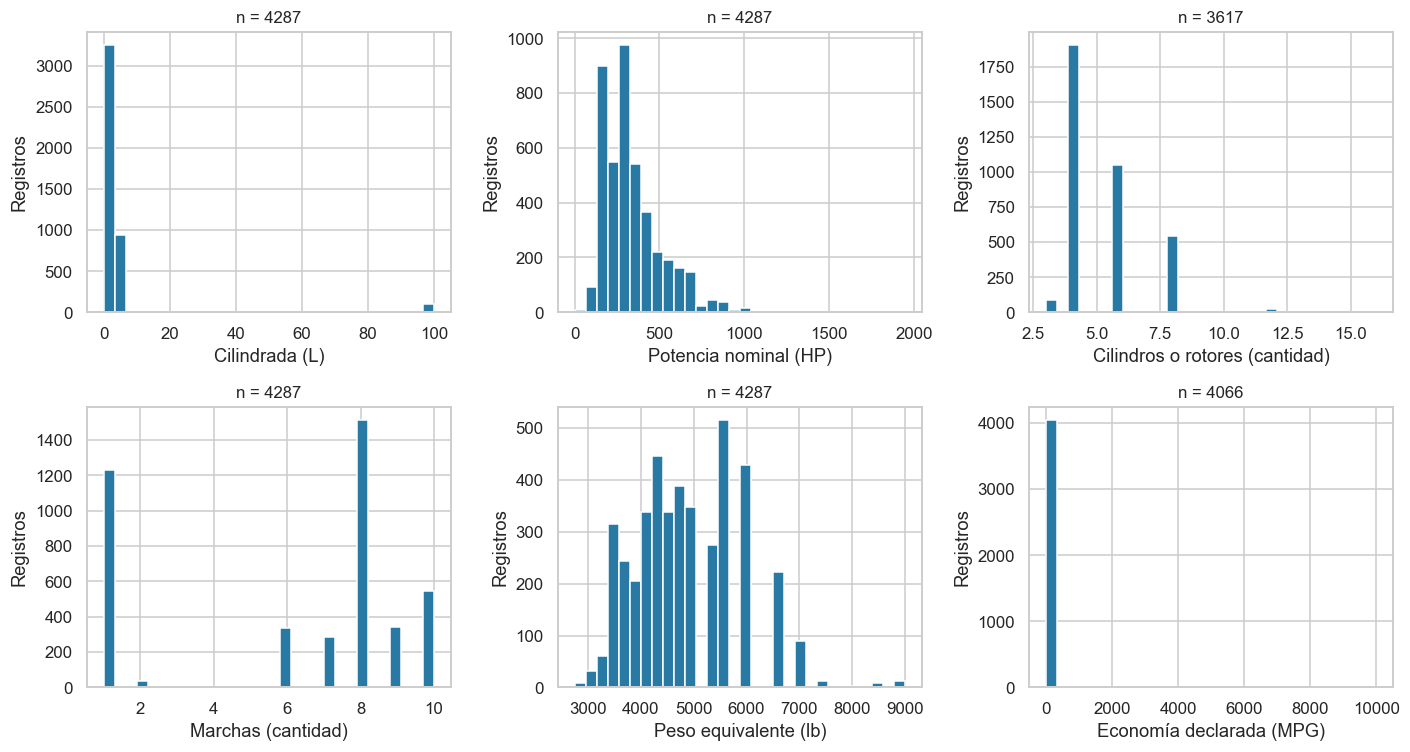

In [6]:
medidas = diccionario.index[diccionario['Escala'].isin(['Continua', 'Discreta'])].tolist()
estadisticas = datos[medidas].describe().T
estadisticas['Rango'] = estadisticas['max'] - estadisticas['min']
estadisticas['RIC'] = estadisticas['75%'] - estadisticas['25%']
estadisticas['Asimetría'] = datos[medidas].skew()
estadisticas['Curtosis (exceso)'] = datos[medidas].kurt()
with pd.option_context('display.max_rows', 50, 'display.max_columns', None):
    display(estadisticas.round(3))

principales = ['Test Veh Displacement (L)', 'Rated Horsepower', '# of Cylinders and Rotors',
               '# of Gears', 'Equivalent Test Weight (lbs.)', 'RND_ADJ_FE']
etiquetas = ['Cilindrada (L)', 'Potencia nominal (HP)', 'Cilindros o rotores (cantidad)',
             'Marchas (cantidad)', 'Peso equivalente (lb)', 'Economía declarada (MPG)']
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col, etiqueta in zip(axes.flat, principales, etiquetas):
    s = datos[col].dropna()
    ax.hist(s, bins=30, color='#2879a3', edgecolor='white')
    ax.set(title=f'n = {len(s)}', xlabel=etiqueta, ylabel='Registros')
plt.tight_layout(); plt.show()

**Lectura global.** El peso equivalente va de 2.750 a 9.000 lb, con mediana 4.750 lb. La potencia nominal tiene mediana 305 HP y alcanza 1.948 HP, con mínimo 1 HP. La cilindrada tiene mediana 2,487 L y máximo 99,999 L. La economía tiene mediana 32,9 MPG y media aproximadamente 65,0 MPG; el máximo cercano a 10.000 y la mezcla de ensayos explican por qué la media global requiere cautela. El histograma a escala completa expone esos extremos, aunque comprima la zona central.

Registros  \
Test Fuel Type Description                    Test Category              
CARB LEV3 E10 Premium Gasoline                FTP                    1   
                                              HWY                    1   
CARB LEV3 E10 Regular Gasoline                SC03                   1   
Cold CO E10 Regular Gasoline (Tier 3)         FTP                    2   
Cold CO Premium (Tier 2)                      FTP                   57   
Cold CO Regular (Tier 2)                      FTP                  160   
E85 (85% Ethanol 15% EPA Unleaded Gasoline)   FTP                    5   
                                              HWY                    5   
                                              US06                   2   
Electricity                                   CD                   563   
                                              FTP                   26   
                                              HWY                   23   
                                              SC03                  23   
                                              US06                  19   
Federal Cert Diesel 7-15 PPM Sulfur           FTP                   51   
                                              HWY                   51   
                                              US06                  48   
Hydrogen 5                                    CD                     2   
                                              FTP                    4   
                                              HWY                    4   
Tier 2 Cert Gasoline                          CD                   130   
                                              FTP                 1270   
                                              HWY                 1255   
                                              SC03                 238   
                                              US06                 343   
Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.) FTP                    1   
                                              HWY                    1   
                                              SC03                   1   

                                                             Disponibles  \
Test Fuel Type Description                    Test Category                
CARB LEV3 E10 Premium Gasoline                FTP                      1   
                                              HWY                      1   
CARB LEV3 E10 Regular Gasoline                SC03                     1   
Cold CO E10 Regular Gasoline (Tier 3)         FTP                      2   
Cold CO Premium (Tier 2)                      FTP                     57   
Cold CO Regular (Tier 2)                      FTP                    160   
E85 (85% Ethanol 15% EPA Unleaded Gasoline)   FTP                      5   
                                              HWY                      5   
                                              US06                     2   
Electricity                                   CD                     563   
                                              FTP                      0   
                                              HWY                      0   
                                              SC03                     0   
                                              US06                     0   
Federal Cert Diesel 7-15 PPM Sulfur           FTP                     51   
                                              HWY                     51   
                                              US06                    48   
Hydrogen 5                                    CD                       2   
                                              FTP                      4   
                                              HWY                      4   
Tier 2 Cert Gasoline                          CD                       0   
                                              FTP                   1270   
                

Vista descriptiva: 922 registros. Se conserva datos sin modificar.


,count,mean,std,min,25%,50%,75%,max
Test Veh Displacement (L),922.0,2.769,1.003,1.2,2.0,2.5,3.445,7.993
Rated Horsepower,922.0,302.444,142.451,1.0,189.0,278.0,375.000,1500.000
# of Cylinders and Rotors,920.0,5.063,1.588,3.0,4.0,4.0,6.000,16.000
# of Gears,922.0,6.852,2.905,1.0,6.0,8.0,8.000,10.000
Equivalent Test Weight (lbs.),922.0,4536.470,823.062,2750.0,3875.0,4500.0,5000.000,6500.000
RND_ADJ_FE,922.0,29.734,11.574,9.5,22.5,26.6,33.475,82.800


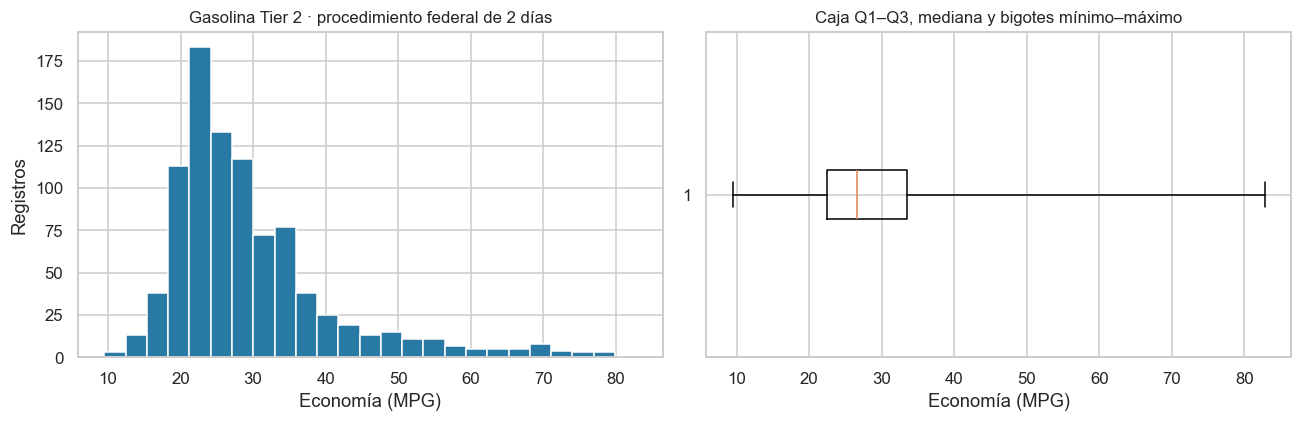

In [7]:
# Describimos economía por combustible y categoría, mostrando cuántos valores faltan.
economia_grupos = datos.groupby(['Test Fuel Type Description','Test Category'])['RND_ADJ_FE'].agg(
    Registros='size', Disponibles='count', Media='mean', Mediana='median',
    Desvio='std', Minimo='min', Maximo='max')
economia_grupos['Nulos'] = economia_grupos['Registros'] - economia_grupos['Disponibles']
with pd.option_context('display.max_rows', 60):
    display(economia_grupos.round(3))

# Elegimos un combustible y UN procedimiento exacto para una comparación más homogénea.
mascara_contexto = (datos['Test Fuel Type Description'].eq('Tier 2 Cert Gasoline') &
                   datos['Test Procedure Description'].eq('Federal fuel 2-day exhaust (w/can load)'))
contexto = datos.loc[mascara_contexto].copy()
print('Vista descriptiva:', len(contexto), 'registros. Se conserva datos sin modificar.')
display(contexto[principales].describe().T.round(3))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(contexto['RND_ADJ_FE'].dropna(), bins=25, color='#2879a3', edgecolor='white')
axes[0].set(xlabel='Economía (MPG)', ylabel='Registros', title='Gasolina Tier 2 · procedimiento federal de 2 días')
# Bigotes mínimo–máximo: los extremos se examinan explícitamente en la sección siguiente.
axes[1].boxplot(contexto['RND_ADJ_FE'].dropna(), vert=False, whis=(0, 100))
axes[1].set(xlabel='Economía (MPG)', title='Caja Q1–Q3, mediana y bigotes mínimo–máximo')
plt.tight_layout(); plt.show()

En la vista de gasolina Tier 2 y procedimiento federal de dos días hay **922 registros**, con mediana **26,6 MPG**, media **29,734 MPG**, Q1 **22,5** y Q3 **33,475 MPG**. La media supera la mediana y aparece una cola hacia valores altos; el máximo es **82,8 MPG**. Esto ilustra cómo el contexto cambia el resumen respecto de la mezcla global. La selección no implica que todos esos registros correspondan a configuraciones independientes ni que este procedimiento represente por sí solo todos los ensayos urbanos del archivo.

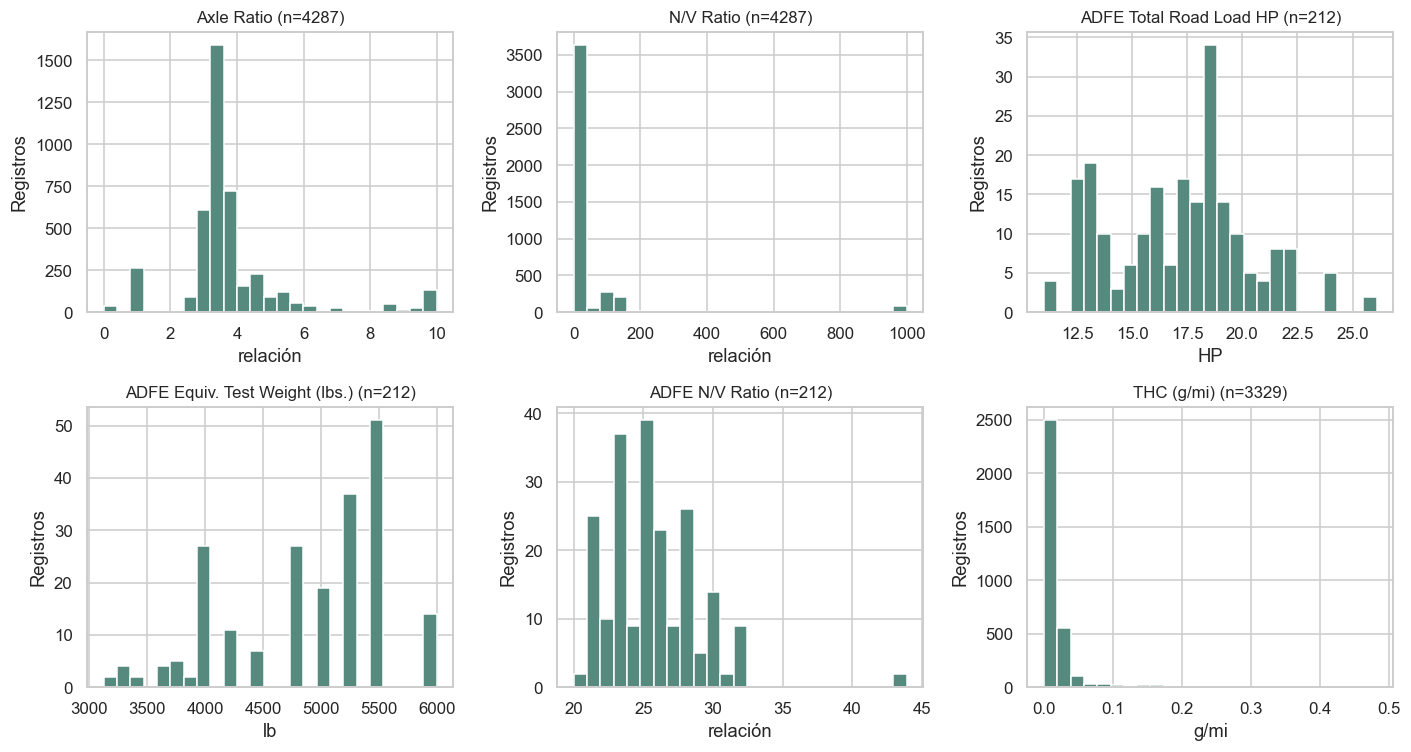

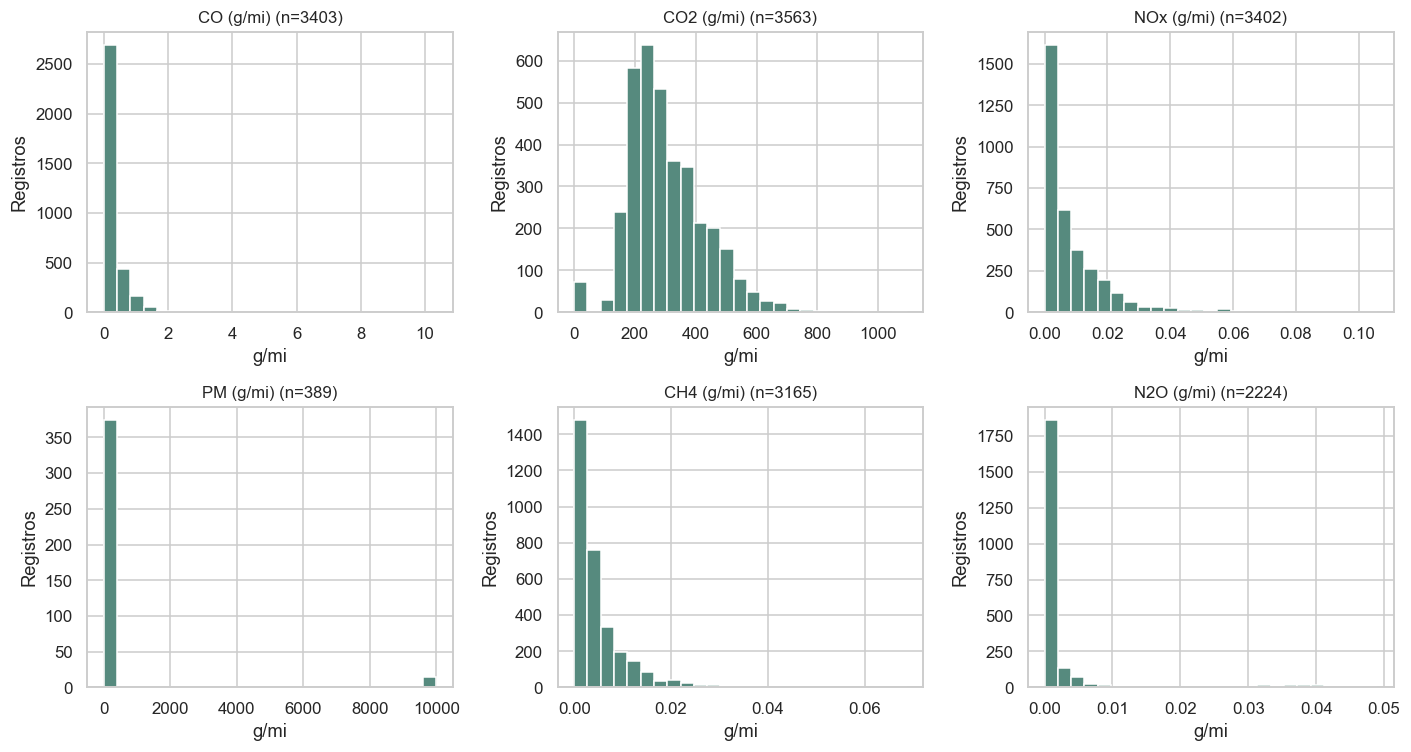

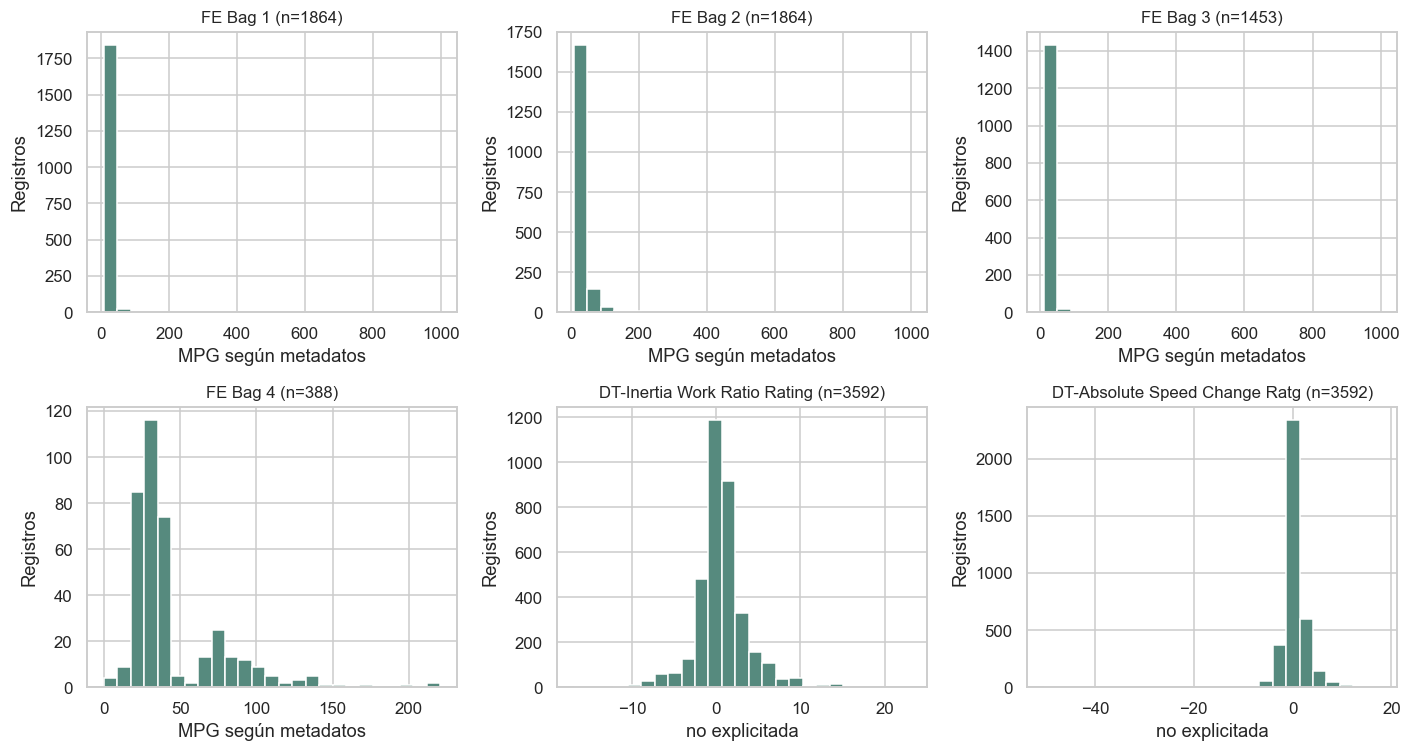

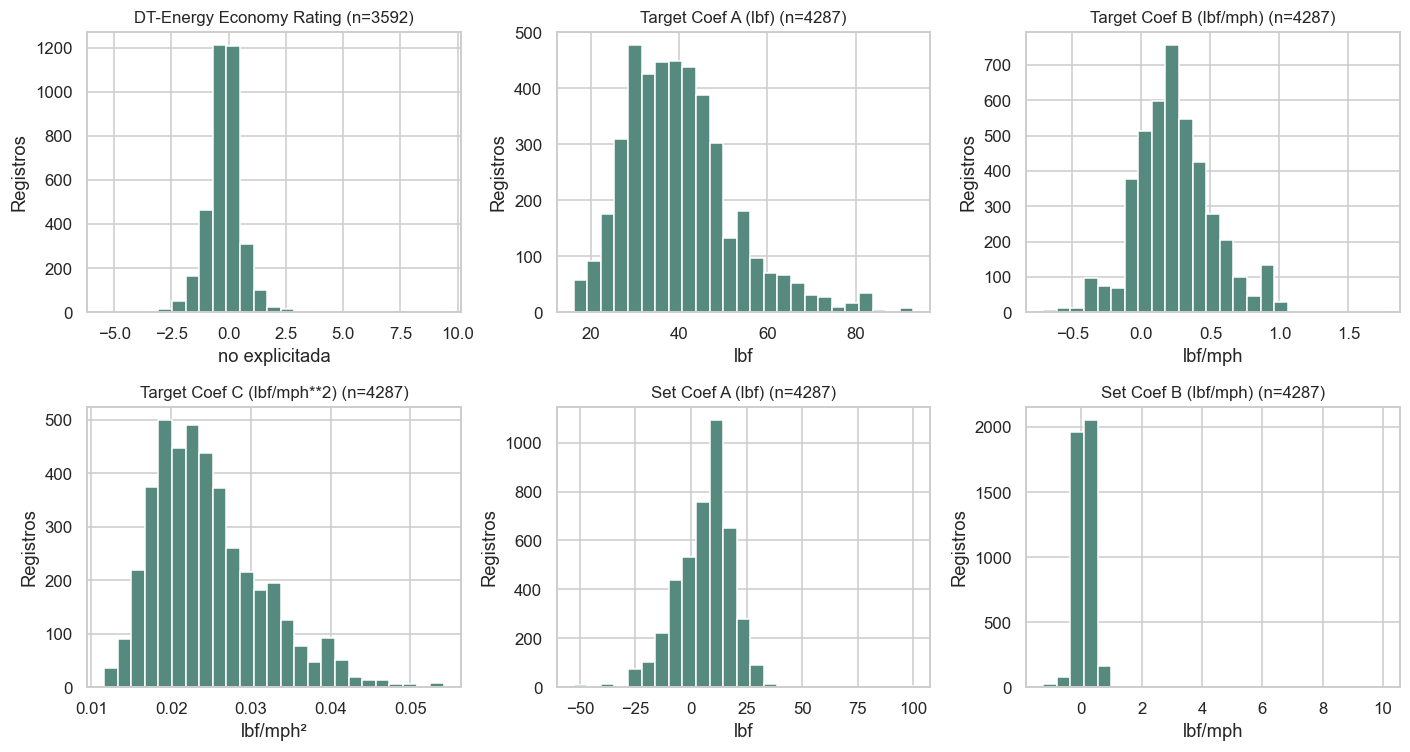

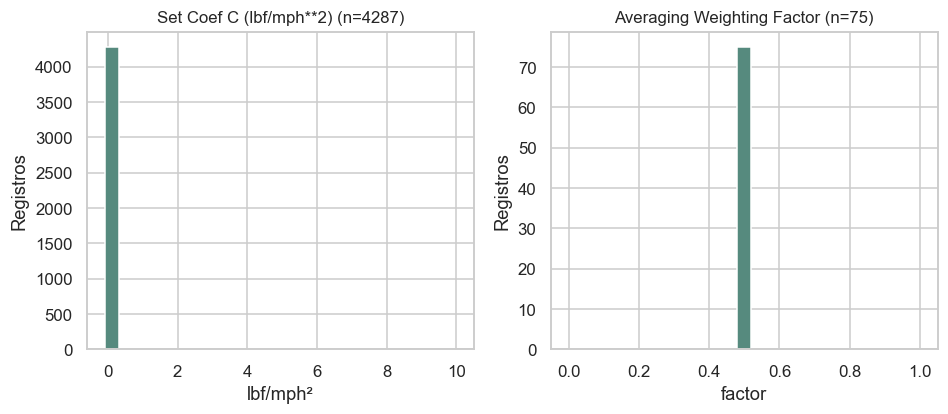

In [8]:
# Distribuciones adicionales: se incluyen las medidas que no aparecieron arriba.
restantes = [c for c in medidas if c not in principales]
for inicio in range(0, len(restantes), 6):
    lote = restantes[inicio:inicio+6]
    fig, axes = plt.subplots(2, 3, figsize=(13, 7))
    for ax, col in zip(axes.flat, lote):
        s = datos[col].dropna()
        ax.hist(s, bins=25, color='#568a7e', edgecolor='white')
        ax.set(title=f'{col} (n={len(s)})', ylabel='Registros')
        ax.set_xlabel(diccionario.loc[col, 'Unidad'])
    for ax in list(axes.flat)[len(lote):]: ax.set_visible(False)
    plt.tight_layout(); plt.show()

En varias distribuciones de emisiones y medidas por bolsa se observan concentraciones cerca de los valores bajos y colas hacia valores mayores; su cobertura es desigual, por lo que no se comparan histogramas como si tuvieran el mismo tamaño de muestra. Las variables ADFE describen únicamente sus 212 registros aplicables. El histograma de PM también muestra valores próximos a 10.000 g/mi, y algunos coeficientes ajustados presentan máximos alejados del resto; son candidatos adicionales a revisar con el contexto de las filas. Los coeficientes mecánicos incluyen valores negativos: el signo de un coeficiente no permite declararlo inválido sin la definición técnica del procedimiento. El factor de ponderación se concentra en un único valor entre los registros informados.

### 1.6. Valores extremos y otras particularidades

Se inspeccionan mínimos, máximos y colas de las distribuciones junto con el contexto de cada fila. Como referencia exploratoria de posición se muestran los percentiles 1 y 99: **estar fuera de ese intervalo no demuestra un error**. El umbral es una elección para revisar colas, no una regla de eliminación. El boxplot anterior usa bigotes mínimo–máximo y no aplica un detector automático de outliers.

Los valores repetidos muy inusuales podrían ser convenciones de registro, resultados de cálculo o errores. Su significado debe verificarse antes de realizar correcciones; por ahora se conservan y se señalan para su revisión.

In [9]:
colas = datos[principales].quantile([0, .01, .25, .5, .75, .99, 1]).T
colas.columns = ['Mínimo','P1','Q1','Mediana','Q3','P99','Máximo']
display(colas.round(4))
cols_revision = ['Represented Test Veh Make','Represented Test Veh Model','Test Vehicle ID',
                 'Test Category','Test Procedure Description','Test Fuel Type Description',
                 'Test Veh Displacement (L)','Rated Horsepower','RND_ADJ_FE','FE_UNIT']
display(datos.nlargest(12, 'RND_ADJ_FE')[cols_revision])
display(datos.nsmallest(8, 'Rated Horsepower')[cols_revision])

senales = pd.Series({
    'Cilindrada exactamente 99.999 L': datos['Test Veh Displacement (L)'].eq(99.999).sum(),
    'Economía mayor a 9000 (valor almacenado 9999.9999999)': datos['RND_ADJ_FE'].gt(9000).sum(),
    'Economía mayor a 4000 y menor a 9000': datos['RND_ADJ_FE'].between(4000,9000).sum(),
    'Economía igual a cero': datos['RND_ADJ_FE'].eq(0).sum(),
    'Potencia igual a 1 HP': datos['Rated Horsepower'].eq(1).sum()
}, name='Registros para revisar')
display(senales.to_frame())
display(pd.crosstab(datos['Test Fuel Type Description'], datos['Test Veh Displacement (L)'].eq(99.999)))

,Mínimo,P1,Q1,Mediana,Q3,P99,Máximo
Test Veh Displacement (L),0.001,0.001,1.991,2.487,3.0,99.999,99.999
Rated Horsepower,1.000,104.000,201.000,305.000,409.0,905.000,1948.000
# of Cylinders and Rotors,3.000,3.000,4.000,4.000,6.0,8.000,16.000
# of Gears,1.000,1.000,1.000,8.000,8.0,10.000,10.000
Equivalent Test Weight (lbs.),2750.000,3250.000,4000.000,4750.000,5500.0,7000.000,9000.000
RND_ADJ_FE,0.000,13.265,24.300,32.900,43.7,171.185,10000.000


,Represented Test Veh Make,Represented Test Veh Model,Test Vehicle ID,Test Category,Test Procedure Description,Test Fuel Type Description,Test Veh Displacement (L),Rated Horsepower,RND_ADJ_FE,FE_UNIT
2461,Lotus,Emira,EDV-25-EVSA6,FTP,Cold CO,Cold CO E10 Regular Gasoline (Tier 3),3.500,400,10000.0,MPG
2462,Lotus,Emira,EDV-25-EVSA6,SC03,SC03,Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.),3.500,400,10000.0,MPG
2463,Lotus,Emira,EDV-25-EVSM6,FTP,Federal fuel 2-day exhaust (w/can load),Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.),3.500,400,10000.0,MPG
2464,Lotus,Emira,EDV-25-EVSM6,HWY,HWFE,Tier 3 E10 Regular Gasoline (9 RVP @Low Alt.),3.500,400,10000.0,MPG
2465,Lotus,Emira,EDV-25-EVSM6,SC03,SC03,CARB LEV3 E10 Regular Gasoline,3.500,400,10000.0,MPG
2466,Lotus,Emira,EDV-25-EVSM6,FTP,Cold CO,Cold CO E10 Regular Gasoline (Tier 3),3.500,400,10000.0,MPG
3021,Pagani SpA,Utopia,ZA9U11EBYYSF76004,FTP,Federal fuel 3-day exhaust,CARB LEV3 E10 Premium Gasoline,6.000,864,10000.0,MPG
3022,Pagani SpA,Utopia,ZA9U11EBYYSF76004,HWY,HWFE,CARB LEV3 E10 Premium Gasoline,6.000,864,10000.0,MPG
3466,LEXUS,RC F,20-UC1A,FTP,Cold CO,Cold CO Premium (Tier 2),4.969,472,4599.1,MPG
3460,LEXUS,RC F,20-UC1A,FTP,Cold CO,Cold CO Premium (Tier 2),4.969,472,4595.3,MPG


,Represented Test Veh Make,Represented Test Veh Model,Test Vehicle ID,Test Category,Test Procedure Description,Test Fuel Type Description,Test Veh Displacement (L),Rated Horsepower,RND_ADJ_FE,FE_UNIT
845,Ford,BRONCO SPORT 4WD,SRE00010,FTP,Federal fuel 2-day exhaust (w/can load),Tier 2 Cert Gasoline,1.500,1,32.8,MPG
846,Ford,BRONCO SPORT 4WD,SRE00010,US06,US06,Tier 2 Cert Gasoline,1.500,1,26.5,MPG
847,Ford,BRONCO SPORT 4WD,SRE00010,HWY,HWFE,Tier 2 Cert Gasoline,1.500,1,49.1,MPG
856,Ford,BRONCO SPORT SASQUATCH,SRE00024,FTP,Federal fuel 2-day exhaust (w/can load),Tier 2 Cert Gasoline,1.500,1,30.8,MPG
857,Ford,BRONCO SPORT SASQUATCH,SRE00024,HWY,HWFE,Tier 2 Cert Gasoline,1.500,1,43.3,MPG
858,Ford,BRONCO SPORT SASQUATCH,SRE00024,US06,US06,Tier 2 Cert Gasoline,1.500,1,24.2,MPG
3711,TOYOTA,MIRAI,21-JD2F,HWY,HWFE,Hydrogen 5,0.001,1,100.1,MPG
3712,TOYOTA,MIRAI,21-JD2F,FTP,CVS 75 and later (w/o can. load),Hydrogen 5,0.001,1,107.0,MPG


,Registros para revisar
Cilindrada exactamente 99.999 L,95
Economía mayor a 9000 (valor almacenado 9999.9999999),8
Economía mayor a 4000 y menor a 9000,2
Economía igual a cero,2
Potencia igual a 1 HP,8


Test Veh Displacement (L),False,True
Test Fuel Type Description,,
CARB LEV3 E10 Premium Gasoline,2,0
CARB LEV3 E10 Regular Gasoline,1,0
Cold CO E10 Regular Gasoline (Tier 3),2,0
Cold CO Premium (Tier 2),57,0
Cold CO Regular (Tier 2),160,0
E85 (85% Ethanol 15% EPA Unleaded Gasoline),12,0
Electricity,559,95
Federal Cert Diesel 7-15 PPM Sulfur,150,0
Hydrogen 5,10,0


**Hallazgos para revisar en el inciso 2:**

- Hay **95 registros con cilindrada 99,999 L**, todos con combustible `Electricity`. Es un patrón de registro asociado a ensayos eléctricos que distorsiona el resumen global; podría responder a una convención de codificación, aunque su significado exacto aún requiere verificación.
- Hay **8 registros con economía almacenada como 9999.9999999**, que una tabla redondeada muestra como 10.000, y otros dos con 4599,1 y 4595,3. Se requiere verificar su interpretación antes de tratarlos como eficiencias físicas.
- Hay **2 valores de economía cero** y **8 registros con potencia 1 HP**. Cero y nulo son distintos; una magnitud inusual requiere inspección y no reemplazo automático.
- Los números de ensayo repetidos y los nulos condicionales requieren criterios diferentes. Ni eliminar todos los nulos ni deduplicar solo por vehículo sería una decisión justificada por este diagnóstico.

### 1.7. Relaciones descriptivas

Usamos el mismo grupo de combustible y procedimiento exacto para explorar relaciones entre medidas técnicas y economía. Pearson resume asociación **lineal**; no demuestra causalidad ni valida las hipótesis de los incisos siguientes. Las correlaciones se calculan por pares disponibles y se acompaña su tamaño de muestra. La repetición de ensayos/configuraciones permanece en la vista, de modo que estos coeficientes describen filas de la base y no una muestra independiente de vehículos.

,RND_ADJ_FE,Test Veh Displacement (L),Rated Horsepower,Equivalent Test Weight (lbs.),# of Cylinders and Rotors,# of Gears
RND_ADJ_FE,1.000,-0.539,-0.659,-0.479,-0.539,-0.718
Test Veh Displacement (L),-0.539,1.000,0.755,0.526,0.922,0.392
Rated Horsepower,-0.659,0.755,1.000,0.511,0.846,0.480
Equivalent Test Weight (lbs.),-0.479,0.526,0.511,1.000,0.501,0.504
# of Cylinders and Rotors,-0.539,0.922,0.846,0.501,1.000,0.387
# of Gears,-0.718,0.392,0.480,0.504,0.387,1.000


,RND_ADJ_FE,Test Veh Displacement (L),Rated Horsepower,Equivalent Test Weight (lbs.),# of Cylinders and Rotors,# of Gears
RND_ADJ_FE,922,922,922,922,920,922
Test Veh Displacement (L),922,922,922,922,920,922
Rated Horsepower,922,922,922,922,920,922
Equivalent Test Weight (lbs.),922,922,922,922,920,922
# of Cylinders and Rotors,920,920,920,920,920,920
# of Gears,922,922,922,922,920,922


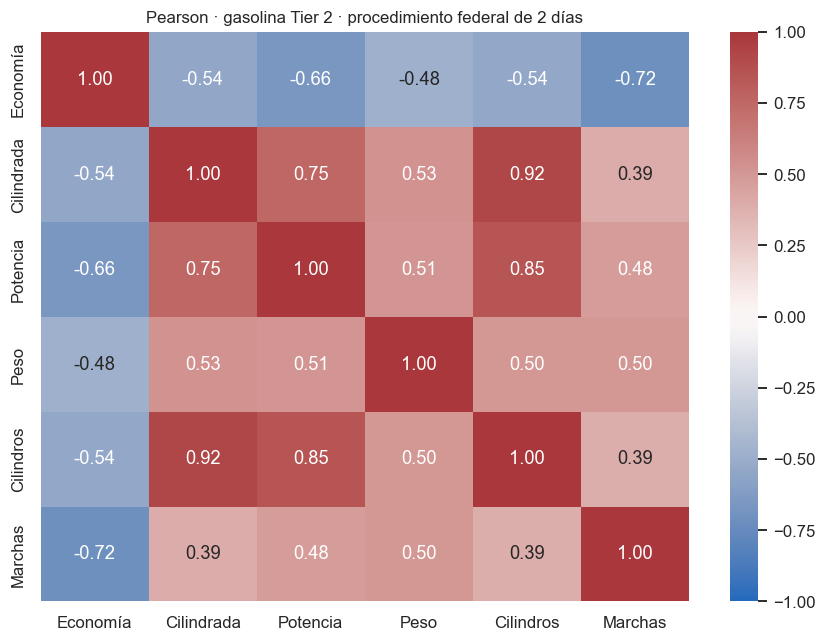

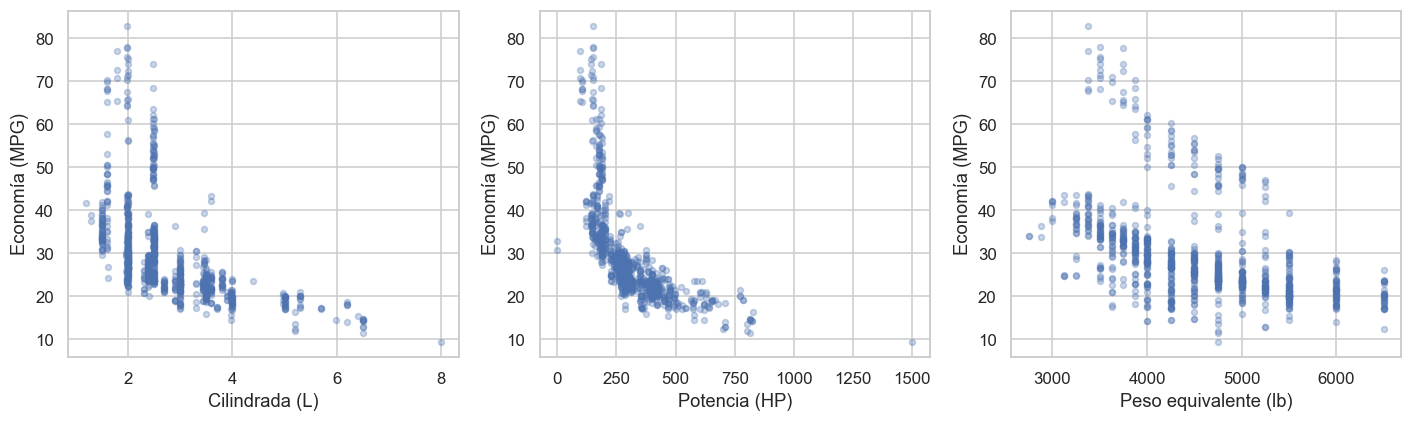

In [10]:
variables_relacion = ['RND_ADJ_FE','Test Veh Displacement (L)','Rated Horsepower',
                      'Equivalent Test Weight (lbs.)','# of Cylinders and Rotors','# of Gears']
correlacion = contexto[variables_relacion].corr(method='pearson')
disponibles = contexto[variables_relacion].notna().astype(int)
pares_disponibles = disponibles.T.dot(disponibles)
display(correlacion.round(3))
display(pares_disponibles)
nombres_cortos = ['Economía','Cilindrada','Potencia','Peso','Cilindros','Marchas']
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(correlacion, annot=True, fmt='.2f', vmin=-1, vmax=1, center=0,
            cmap='vlag', xticklabels=nombres_cortos, yticklabels=nombres_cortos, ax=ax)
ax.set_title('Pearson · gasolina Tier 2 · procedimiento federal de 2 días')
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, x, etiqueta in zip(axes, variables_relacion[1:4], ['Cilindrada (L)','Potencia (HP)','Peso equivalente (lb)']):
    ax.scatter(contexto[x], contexto['RND_ADJ_FE'], alpha=.3, s=15)
    ax.set(xlabel=etiqueta, ylabel='Economía (MPG)')
plt.tight_layout(); plt.show()

En esta vista aparecen asociaciones lineales negativas de la economía con potencia (**r ≈ −0,659**), cilindrada (**−0,539**) y peso (**−0,479**). Los gráficos muestran dispersión alrededor de esas tendencias y puntos alejados. Potencia y cilindrada se asocian positivamente entre sí (**0,755**). Son resultados descriptivos condicionados al grupo elegido, sin pruebas de significación ni conclusión causal.

### 1.8. Conclusiones del inciso 1

La base reúne **4.287 registros de ensayos, 67 atributos y 1.448 configuraciones**, todos de año modelo 2025. Combina fuentes de energía y procedimientos diferentes, con predominio de gasolina Tier 2. 

No hay filas completamente duplicadas, pero los **4.014 números de ensayo** no identifican de manera única las filas. Este hecho y la multiplicidad de ensayos por configuración deben considerarse antes de cualquier inferencia sobre vehículos.

Los faltantes más frecuentes corresponden a información condicional, como ADFE y promediado. En cambio, las ausencias de economía y emisiones requieren revisión según procedimiento y combustible. La cobertura de una medida debe acompañar siempre a sus estadísticas.

Las distribuciones globales mezclan grupos y contienen extremos relevantes: cilindrada 99,999 L en registros eléctricos, economía cercana a 10.000, potencias de 1 HP y economías cero. La media global de economía resulta sensible a esos valores. En un grupo más homogéneo, gasolina Tier 2 y procedimiento federal de dos días, la mediana es 26,6 MPG y se observan asociaciones negativas con potencia, cilindrada y peso.

El inciso deja un diagnóstico y una lista concreta de aspectos para investigar. **No se efectuó limpieza, no se imputaron faltantes ni se validaron hipótesis**. Queda pendiente verificar el significado de los valores extremos y las causas de las ausencias que no se explican por la aplicabilidad de cada atributo.

## 2. Limpieza de la base

Pendiente de desarrollo. Se registrarán las acciones implementadas, su justificación y el efecto sobre los datos.

## 3. Hipótesis propuestas

Pendiente de desarrollo. Se formularán una hipótesis univariada, una bivariada y una multivariada, con su justificación de dominio.

## 4. Validación de hipótesis

Pendiente de desarrollo. Se evaluarán las tres hipótesis propuestas y las tres indicadas en el enunciado. Para cada una se presentarán la técnica elegida, sus condiciones de aplicación, los resultados y la conclusión.